
# Face Recognition Pipeline & Overlay Visualization
Generates/loads reference embeddings and visualizes detected faces, bounding boxes,
and cosine similarity scores across a folder of test images.

### Imports

In [11]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Locate project root automatically regardless of Jupyter's working directory
ROOT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.helpers.aura_face_extractor import AuraFaceExtractor
from src.helpers.insight_face_extractor import InsightFaceExtractor
from src.scripts.generate_face_embeddings import get_face_embeddings
from src.scripts.get_image_face_labels import identify_personalities, load_reference_embeddings

### Config

In [15]:
BACKEND = "auraface"  # "auraface" or "insightface"
PEOPLE_DIR = ROOT_DIR / "images" / "people"
TEST_DIR = ROOT_DIR / "images" / "targets"
EMBEDDINGS_PATH = ROOT_DIR / "output" / "embeddings" / f"notebook_{BACKEND}.npz"

RECOMPUTE_EMBEDDINGS = True  # Set False to reuse existing .npz file
THRESHOLD = 0.35
DET_THRESH = 0.40
DET_SIZE = (640, 640)
CTX_ID = -1  # -1 for CPU, >=0 for GPU

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

### Generate embeddings

In [10]:
if BACKEND == "auraface":
    extractor = AuraFaceExtractor(det_thresh=DET_THRESH, det_size=DET_SIZE, ctx_id=CTX_ID)
else:
    extractor = InsightFaceExtractor(det_thresh=DET_THRESH, det_size=DET_SIZE, ctx_id=CTX_ID)

# 2. Generate (or load) centroid embeddings
if RECOMPUTE_EMBEDDINGS or not EMBEDDINGS_PATH.exists():
    embeddings_dict = get_face_embeddings(extractor, str(PEOPLE_DIR))
    EMBEDDINGS_PATH.parent.mkdir(parents=True, exist_ok=True)
    np.savez(EMBEDDINGS_PATH, **embeddings_dict)  # type: ignore
    print(f"Saved centroid embeddings for {len(embeddings_dict)} identities -> {EMBEDDINGS_PATH}")

ref_names, ref_matrix = load_reference_embeddings(EMBEDDINGS_PATH)
print(f"Loaded identities: {ref_names}")

[ WARN:0@311.447] global net_impl_backend.cpp:388 setPreferableTarget Targets are not supported by the new graph engine for now


Saved centroid embeddings for 3 identities -> /home/robin/EPFL/MA3/machineLearning/Who_that/output/embeddings/notebook_auraface.npz
Loaded identities: ['anna', 'edouard', 'katia']


### Detect

In [16]:
image_paths = sorted(
    p for p in TEST_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

predictions = []
for img_path in image_paths:
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print(f"[warn] Could not read {img_path}")
        continue

    faces = extractor.get_all_embeddings(img_bgr)
    recognized = identify_personalities(
        faces,
        ref_names,
        ref_matrix,
        threshold=THRESHOLD,
        min_face_size=0,
    )
    predictions.append(
        {
            "name": str(img_path.relative_to(TEST_DIR)),
            "img_bgr": img_bgr,
            "faces": faces,
            "recognized": recognized,
        }
    )

print(f"Processed {len(predictions)} images.")

Processed 6 images.


### Visualize

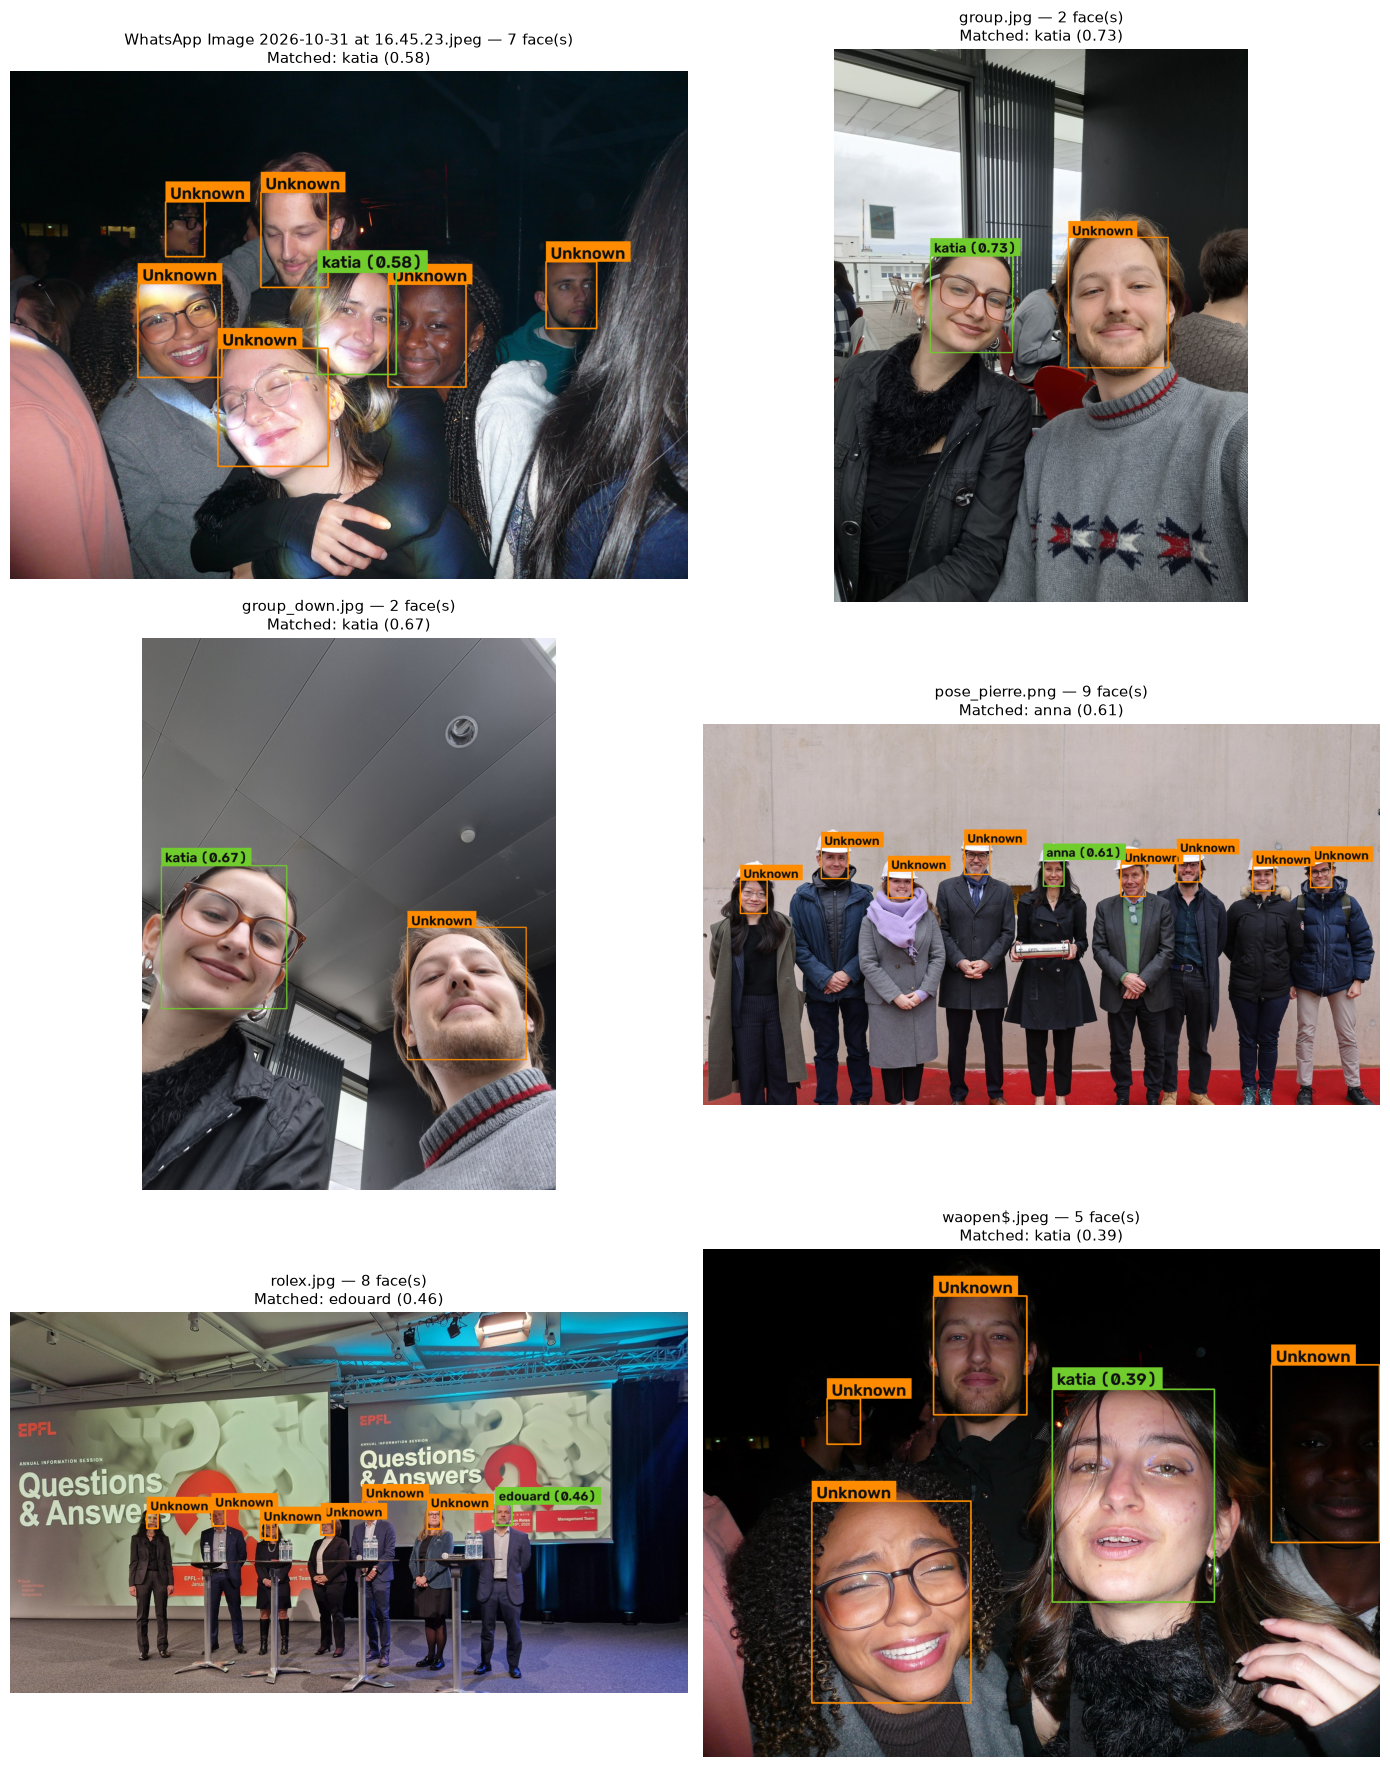

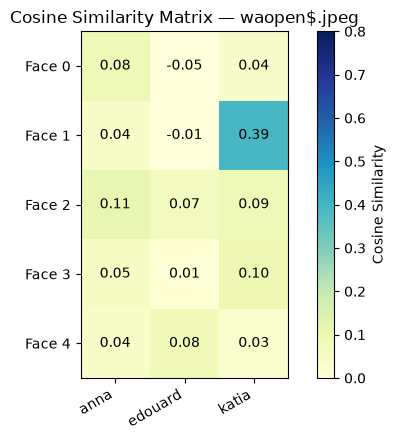

In [17]:
def draw_overlays(img_bgr: np.ndarray, faces: list[dict], recognized: list[dict]) -> np.ndarray:
    canvas = img_bgr.copy()
    h, w = canvas.shape[:2]

    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = max(0.55, min(w, h) / 900.0)
    thickness = max(2, int(round(font_scale * 2.2)))
    pad = max(6, int(round(font_scale * 8)))

    matched_by_bbox = {tuple(p["bbox"]): p for p in recognized}

    # Draw unmatched faces first in muted orange, then matched personalities on top in green
    ordered_faces = sorted(faces, key=lambda f: tuple(f["bbox"]) in matched_by_bbox)

    for face in ordered_faces:
        bbox_key = tuple(face["bbox"])
        x1, y1, x2, y2 = [int(round(v)) for v in bbox_key]
        match = matched_by_bbox.get(bbox_key)

        if match is not None:
            color = (46, 204, 113)  # BGR green
            label = f"{match['name']} ({match['similarity']:.2f})"
        else:
            color = (0, 140, 255)  # BGR orange
            label = "Unknown"

        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, thickness)

        (tw, th), baseline = cv2.getTextSize(label, font, font_scale, thickness)
        box_h = th + baseline + pad

        # Keep label inside frame if face touches the top border
        top = y1 - box_h if y1 - box_h >= 0 else y1
        bottom = top + box_h
        right = min(w, x1 + tw + pad * 2)

        cv2.rectangle(canvas, (x1, top), (right, bottom), color, cv2.FILLED)
        cv2.putText(
            canvas,
            label,
            (x1 + pad, bottom - baseline - pad // 2),
            font,
            font_scale,
            (15, 15, 15),
            thickness,
            cv2.LINE_AA,
        )

    return canvas

# %%
# 5. Visualize all annotated test images in a grid
cols = 2
rows = max(1, (len(predictions) + cols - 1) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(14, 6 * rows), squeeze=False)

for idx, item in enumerate(predictions):
    ax = axes[idx // cols][idx % cols]
    annotated_bgr = draw_overlays(item["img_bgr"], item["faces"], item["recognized"])
    ax.imshow(cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB))

    matches_str = (
        ", ".join(f"{p['name']} ({p['similarity']:.2f})" for p in item["recognized"])
        or "None"
    )
    ax.set_title(
        f"{item['name']} — {len(item['faces'])} face(s)\nMatched: {matches_str}",
        fontsize=11,
    )
    ax.axis("off")

# Hide unused subplots
for idx in range(len(predictions), rows * cols):
    axes[idx // cols][idx % cols].axis("off")

plt.tight_layout()
plt.show()

# %%
# 6. Optional: Inspect full cosine similarity breakdown for a specific image
IMAGE_INDEX = -1  # -1 = last image in TEST_DIR
sample = predictions[IMAGE_INDEX]

if sample["faces"]:
    cand = np.vstack([f["embedding"] for f in sample["faces"]]).astype(np.float32)
    cand /= np.linalg.norm(cand, axis=1, keepdims=True)
    scores = cand @ ref_matrix.T  # (N_faces, N_identities)

    fig, ax = plt.subplots(figsize=(max(6, len(ref_names) * 1.6), max(2.5, len(sample["faces"]) * 0.9)))
    im = ax.imshow(scores, cmap="YlGnBu", vmin=0.0, vmax=0.8)
    ax.set_xticks(range(len(ref_names)), labels=ref_names, rotation=30, ha="right")
    ax.set_yticks(range(len(sample["faces"])), labels=[f"Face {i}" for i in range(len(sample["faces"]))])
    ax.set_title(f"Cosine Similarity Matrix — {sample['name']}")

    for i in range(scores.shape[0]):
        for j in range(scores.shape[1]):
            ax.text(j, i, f"{scores[i, j]:.2f}", ha="center", va="center", color="black")

    fig.colorbar(im, ax=ax, label="Cosine Similarity")
    plt.tight_layout()
    plt.show()